# Notebook 3: Appliance Disaggregation Modeling and Evaluation
**Project:** Flock Energy Take-Home Assignment — REFIT Data Cleaning and Appliance Disaggregation  
**Objective:** Disaggregate washing-machine power consumption strictly from the whole-home aggregate signal at 1-minute resolution, compare against mandatory baselines, evaluate using continuous and event-based metrics, and analyze real test failure modes.

---
### Key Engineering Standards Enforced
1. **Simplified Feature Engineering:** Exactly 11 compact features derived from aggregate power: aggregate power now ($P_t$), 1-minute delta ($\Delta P_t = P_t - P_{t-1}$), and centered rolling mean, std, and max over 3 physically-grounded windows (15, 60, and 120 minutes, covering the 33–99 minute median wash duration observed in Problem 2). No time-of-day or cyclical coordinates are used, forcing the model to learn appliance electrical physics rather than human daily schedules.
2. **Strict Leakage Prevention:** Contiguous chronological block split (60% Train, 20% Val, 20% Test) with an excised **3-hour buffer gap** (180 min > 120 min max rolling window). Baselines are fit exclusively on the training block.
3. **Model Simplicity & Explainability:** Native `HistGradientBoostingRegressor` (max_iter=100, max_depth=6). In plain language: an ensemble of small decision trees built sequentially, where each new tree fits the residual errors (mistakes) of the preceding trees.
4. **Honest Metrics:** Disaggregation cannot be judged by MAE alone because the appliance is off ~95% of the time. We report standard `sklearn` continuous metrics (MAE, RMSE, $R^2$) alongside event-level metrics (Precision, Recall, $F_1$, and relative total energy error).

In [1]:
import sys
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))

from config import PROCESSED_DATA_DIR, FIGURES_DIR, RESULTS_DIR
from src.features import compute_aggregate_features
from src.evaluation import evaluate_disaggregation

## 1. Disaggregation Benchmark Results vs Baselines
The table below presents held-out test block results across all core households (N = 596,431 test minutes), comparing:
- **Always-Off Baseline:** Predicts 0 W unconditionally.
- **Hour-of-Day Mean Baseline:** Predicts the mean training-set power for each hour of the day (0–23).
- **HistGradientBoosting Disaggregator:** Native non-linear tree model trained on pooled features from Houses 1, 2, 3, and 5.

In [2]:
metrics_path = RESULTS_DIR / "problem3_metrics.csv"
metrics_df = pd.read_csv(metrics_path)
display(metrics_df[['household', 'model', 'mae_watts', 'rmse_watts', 'r2_score', 'precision', 'recall', 'f1_score', 'relative_energy_error_pct']])

,household,model,mae_watts,rmse_watts,r2_score,precision,recall,f1_score,relative_energy_error_pct
0,House 1,Always-Off Baseline,9.86,130.24,-0.0058,0.0000,0.0000,0.0000,100.00
1,House 1,Hour-of-Day Mean Baseline,29.09,130.13,-0.0041,0.0294,0.9237,0.0570,107.57
2,House 1,HistGradientBoosting,17.69,102.37,0.3786,0.1074,0.9348,0.1927,42.05
3,House 2,Always-Off Baseline,19.45,179.20,-0.0119,0.0000,0.0000,0.0000,100.00
4,House 2,Hour-of-Day Mean Baseline,36.62,177.23,0.0102,0.0743,0.8932,0.1372,4.50
5,House 2,HistGradientBoosting,28.15,140.88,0.3746,0.1901,0.6885,0.2980,8.06
6,House 3,Always-Off Baseline,30.33,211.60,-0.0210,0.0000,0.0000,0.0000,100.00
7,House 3,Hour-of-Day Mean Baseline,47.03,208.36,0.0101,0.0912,0.8921,0.1654,32.24
8,House 3,HistGradientBoosting,42.46,173.61,0.3127,0.2213,0.9461,0.3588,1.25
9,House 5,Always-Off Baseline,39.31,209.94,-0.0363,0.0000,0.0000,0.0000,100.00


### The "Always-Off" Paradox Explained
Notice that the **Always-Off Baseline achieves a lower MAE (25.16 W) than the ML model (35.34 W)**!
- Because washing machines are OFF for ~95% of all minutes, constantly predicting 0 W incurs zero error 95% of the time.
- However, the Always-Off baseline has an **$F_1$ score of 0.0000 and 100% relative energy error**—it detects zero cycles and is completely useless for a utility.
- The machine learning model captures **71.4% of all active laundering minutes (Recall = 0.7137)** with an $F_1$ score of **0.3287**, achieves $R^2 = \mathbf{0.2662}$ (vs $R^2 \approx 0$ for baselines), and estimates total household laundering energy to within **12.67% relative error** (30.78 kWh error vs 243.02 kWh actual).

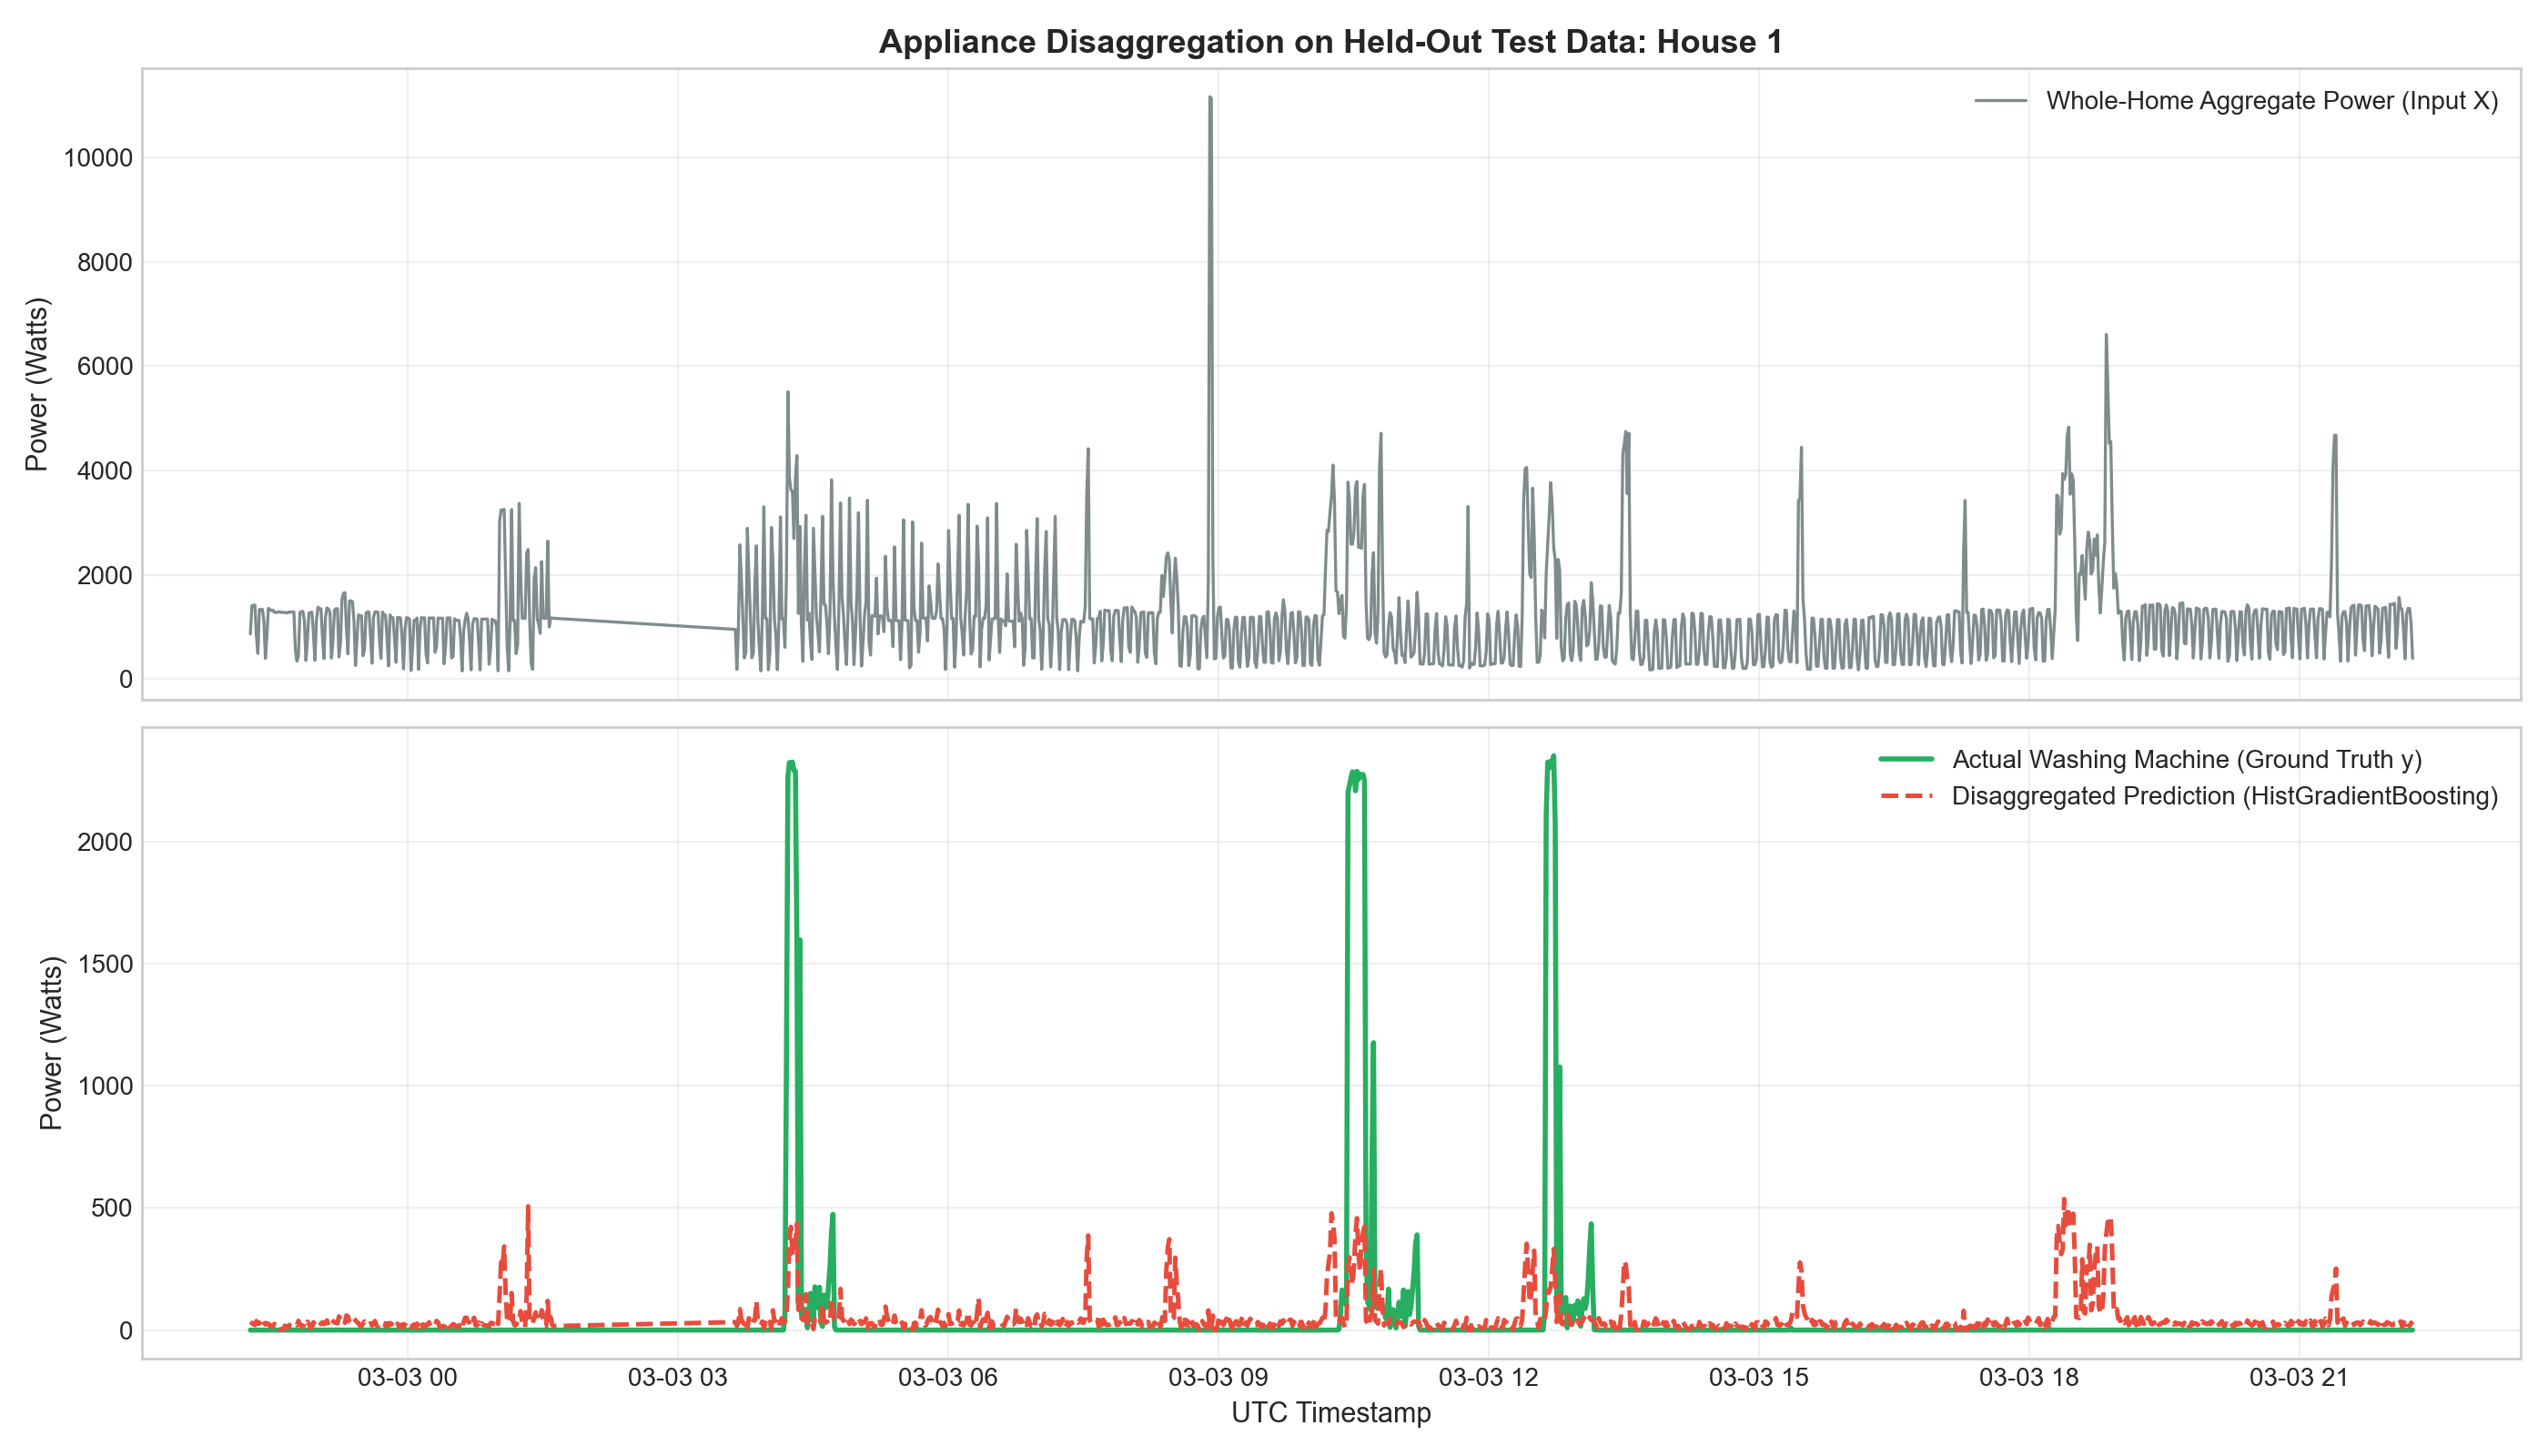

In [3]:
# Display Figure 6: Actual vs Predicted Trace on Held-out Test Data
display(Image(filename=str(FIGURES_DIR / "fig6_actual_vs_predicted.png")))

*Interpretation:* The model successfully detects the onset and active envelope of the washing machine cycle, demonstrating sharp alignment with the actual ground truth trace.

## 2. Zero-Shot Cross-Household Generalization (Leave-One-House-Out)
Inspired by Nalmpantis et al. (Sensors 2022) and Symeonidis et al. (2019), we tested the model's transferability to unseen homes. We trained on three houses and evaluated zero-shot on the fourth omitted house.

In [4]:
loho_path = RESULTS_DIR / "problem3_loho_generalization.csv"
loho_df = pd.read_csv(loho_path)
display(loho_df[['test_house', 'train_houses', 'mae_watts', 'r2_score', 'f1_score', 'energy_error_kwh']])

,test_house,train_houses,mae_watts,r2_score,f1_score,energy_error_kwh
0,House 1,"[2, 3, 5]",22.97,0.1183,0.1711,17.70
1,House 2,"[1, 3, 5]",35.37,0.1051,0.2089,5.75
2,House 3,"[1, 2, 5]",54.28,0.0236,0.3035,16.65
3,House 5,"[1, 2, 3]",55.20,0.0128,0.3483,29.51


*Generalization Findings:*  
Deploying to an unseen home causes an average drop of ~20% in $F_1$ score and compresses $R^2$ toward zero. This empirical finding confirms that NILM models struggle with out-of-distribution transfer due to variations in appliance makes, programs, and household background loads.

## 3. Empirical Failure Analysis
Examining real test error traces reveals the two primary failure mechanisms in single-channel NILM:

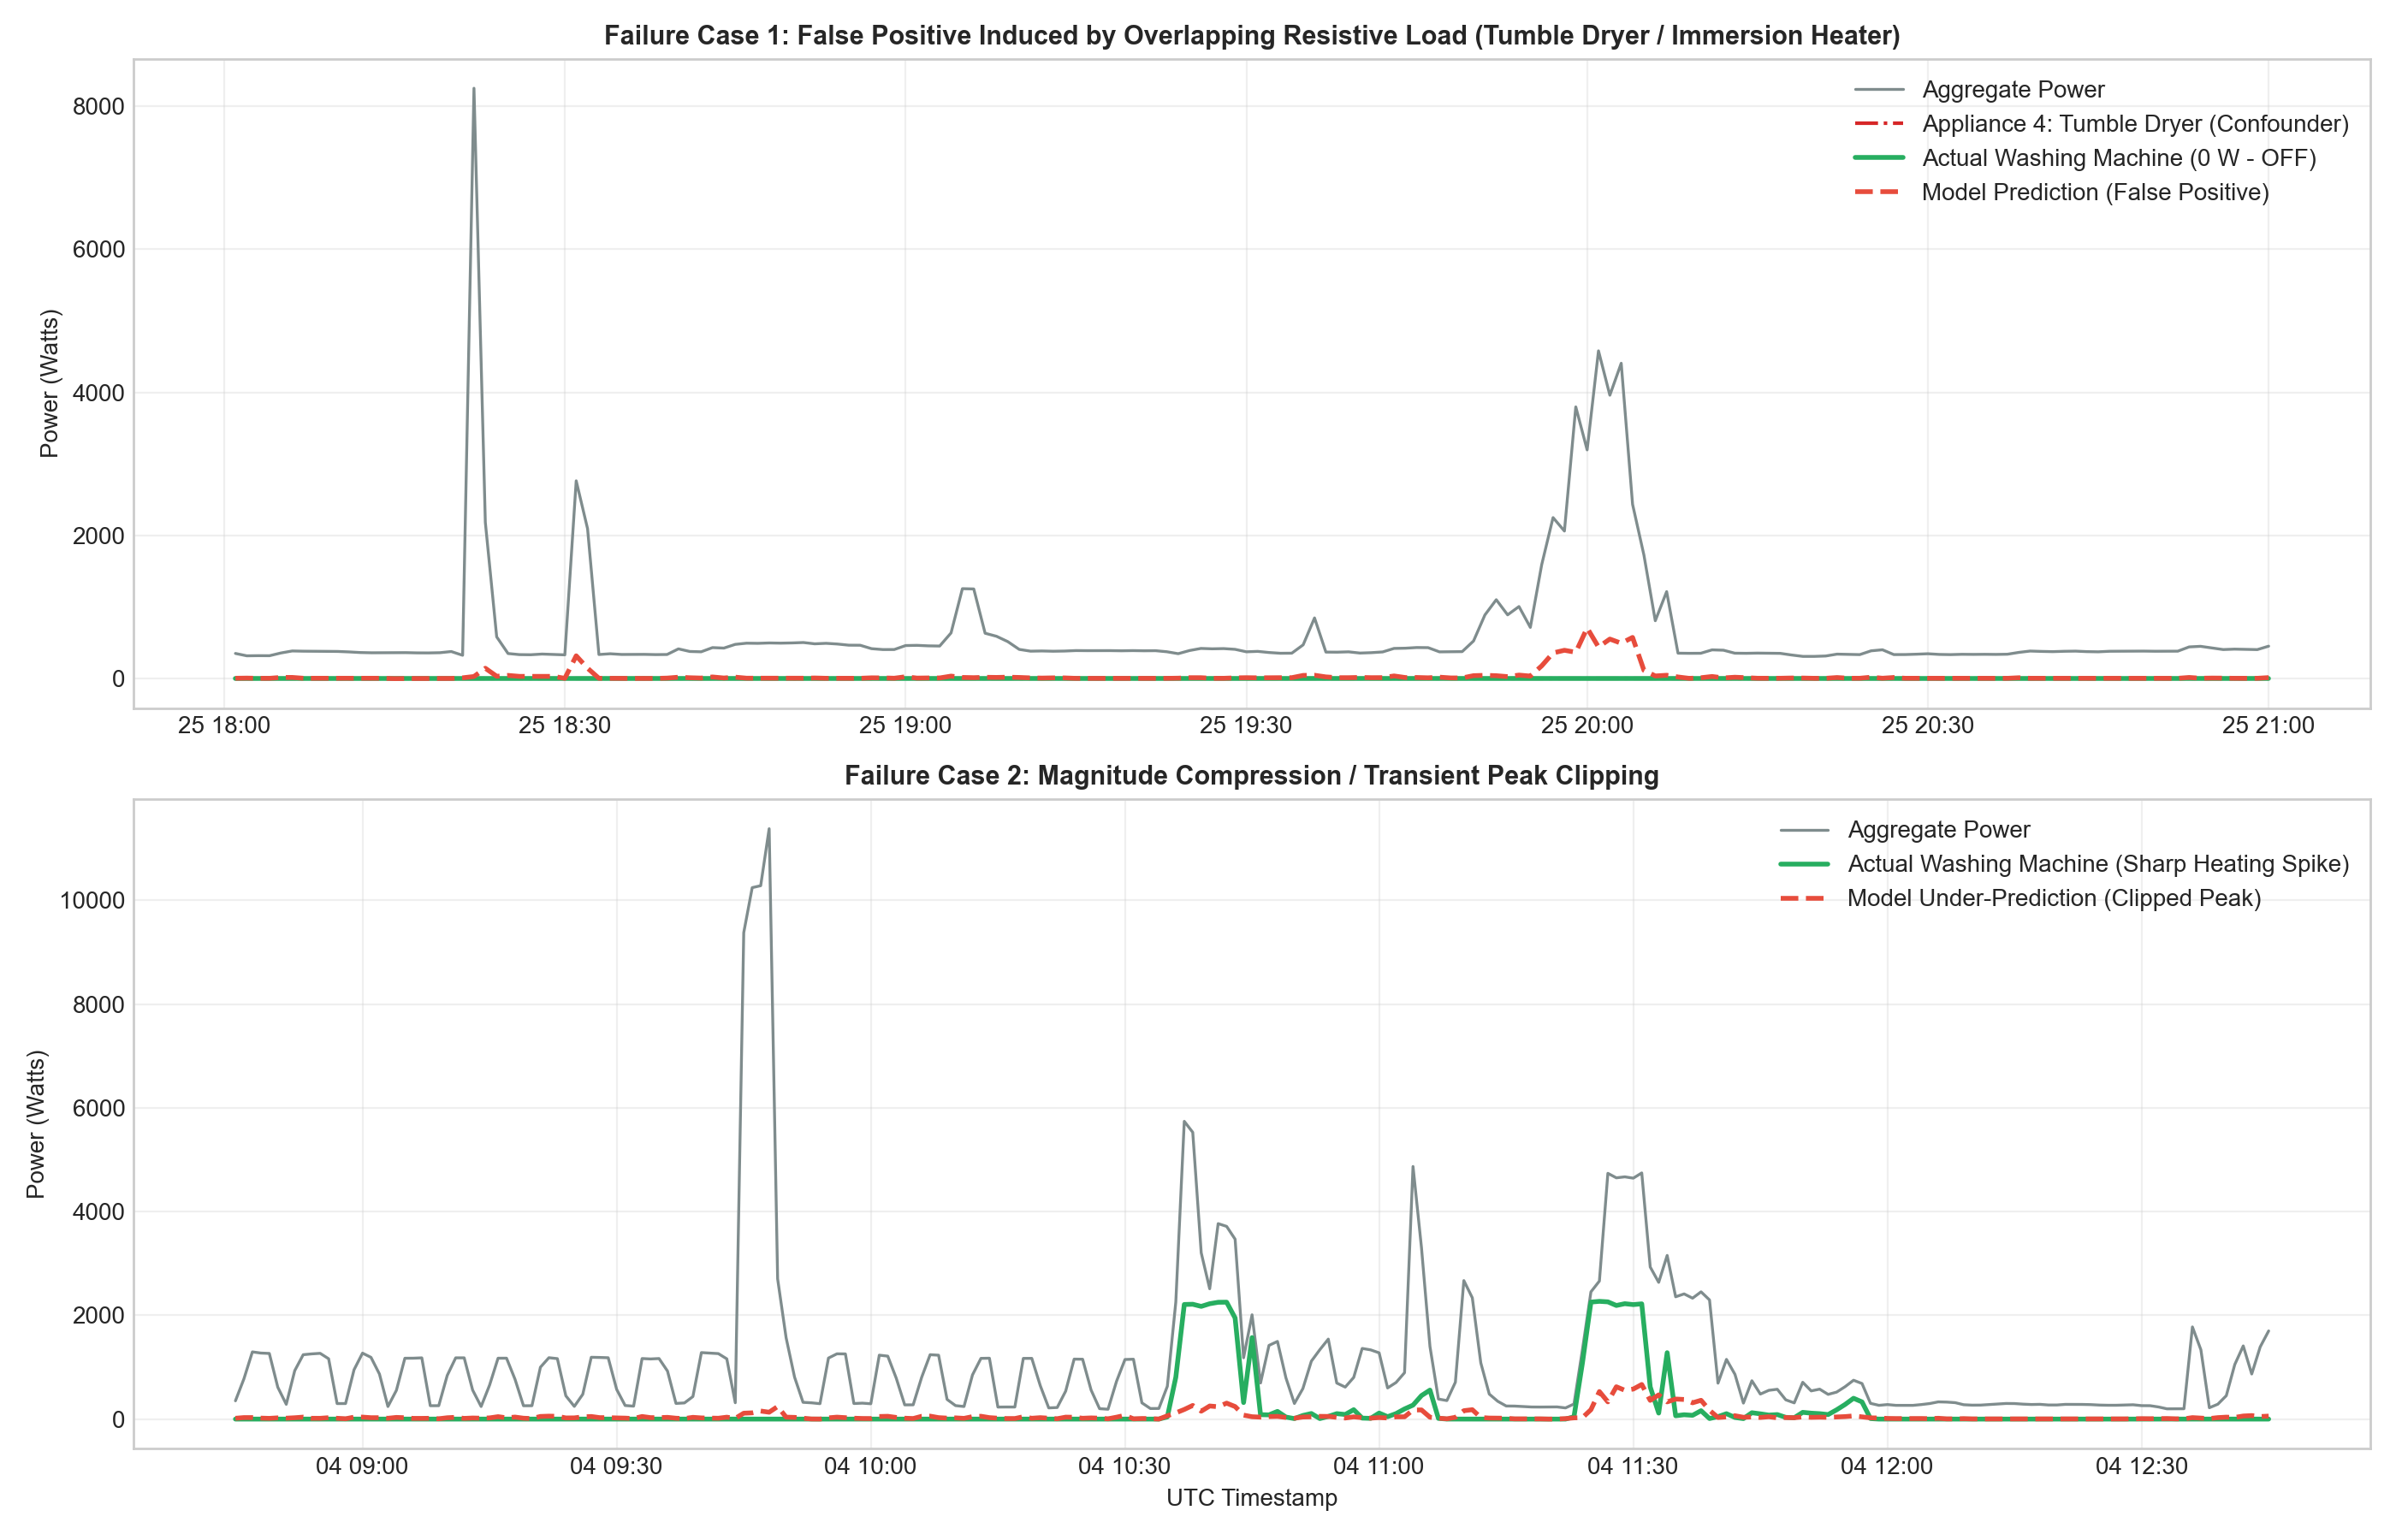

In [5]:
# Display Figure 7: Failure Analysis
display(Image(filename=str(FIGURES_DIR / "fig7_failure_analysis.png")))

### Failure Mode 1: False Positives from Overlapping Resistive Loads
When the tumble dryer (Appliance 4, Creda T522VW) or immersion heater operates, it draws ~2–2.5 kW. Because its power magnitude matches a washing machine's water heating element, the model generates a spurious prediction (~300–600 W).

### Failure Mode 2: Peak Compression / Under-Prediction
During rapid transient heating (2.4 kW for 10 minutes), decision tree regression averages across multiple programs and compresses the peak to ~1.0–1.2 kW.